**Lab 5: FIR Filtering 2**

The goal of this lab is to study the response of FIR filters to inputs such as complex exponentials and sinusoids. In the experiments of this lab, you will use `np.convolve()` to implement filters and `freqz()` to obtain the filter’s frequency response. As a result, you should learn how to characterize a filter by knowing how it reacts to different frequency components in the input.
This lab also introduces two practical filters: bandpass filters and nulling filters.
Bandpass filters can be used to detect and extract information from complex signals,
e.g., tones in a touch-tone telephone dialer. Nulling filters can be used to remove
sinusoidal interference, e.g., jamming signals in a radar.

In [1]:
import os
import numpy as np
import librosa
import IPython.display as ipd
from scipy import signal
import matplotlib.pyplot as plt

from util import load_audio, plot_signals, plot_spectrogram, plot_mean_spectrogram

1.1. First, let's replicate what we did until now. Copy the functions synthesize and envelope and obtain the synthesis from the last lab.

In [2]:
def synthesize(f0, phi, Ak, t):
  y = 0
  for k in range(1, len(Ak) + 1):
    y += Ak[k-1] * np.cos(2*np.pi*k*f0*t + k*phi - (k-1)*np.pi/2)
  return y


def envelope(x, N):
    if N < 1:
      raise ValueError("N must be at least 1")

    # Step 1: Full-wave rectifier (absolute value)
    # Step 2: Apply N-point averaging filter to the rectified signal
    rectified_signal = np.abs(x)
    filter_coeffs = np.ones(N) / N
    envelope_signal = np.convolve(rectified_signal, filter_coeffs, mode='same')

    return envelope_signal

filepath = "reference.wav"
ref, fs = load_audio(filepath)
weights = [0.257, 1.0, 0.201, 0.192, 0.0146, 0.009, 0.004] # These are the amplitudes of each of the harmonics (Given by the peaks)
y = synthesize(145, np.pi/2, weights, np.arange(0, len(ref)/fs, 1/fs))*envelope(ref, 200)


1.2 Plot both reference and synthesised signal.

In [3]:
plot_signals([ref, np.abs(ref), envelope(ref, 200)], fs, 0, 5)

---

**2. Averaging filter**

Now let's analyze the frequency response of the average filter used in the envelope function. The Scipy Python module has a function called *freqz()* for computing the frequency
response of a discrete-time LTI system. The following Python statements show how to
use freqz to compute and plot both the magnitude (absolute value) and the phase of
the frequency response of a four-point averaging system as a function of ω in the range − π ≤ ω ≤ π :

In [4]:
from util import plot_frequency_response

ww = np.arange(-np.pi, np.pi, np.pi/500)
_, HH = signal.freqz([1/4]*4, 1, ww)


plot_frequency_response(ww, HH)

For FIR filters, the second argument of `freqz(-, 1,- )` must always be equal to 1. The frequency vector ww should cover an interval of length 2π for ω , and its spacing must be fine enough to give a smooth curve for H(ejω) . Note: we will always use capital H for the frequency response.

2.1 Use the `freqz` and `plot_frequency_response` functions to plot the frequency response of the averaging filter of your envelope function.



In [5]:
# Write your code here


N = 10
filter_coeffs = np.ones(N) / N
Fy= np.convolve(y, filter_coeffs, "same") 

w, h = signal.freqz(filter_coeffs, 1, ww)
plot_frequency_response(w, h)


2.2 Looking at the frequency responses, what are the main differences between your filter and the four-point averaging filter. What happens when the value N is increased?

When the value N is increased, mroe periodic changes are shown. 

---

**3. Nulling Filters for Rejection**

Nulling filters are filters that completely eliminate some frequency components. If the frequency is $\omega=0$ or $\omega=\pi$ then a two-point FIR filter will do the nulling. The simplest possible general nulling filter can have as few as three coefficients. If $\omega_n$ is the desired nulling frequency, then the following length-3 FIR filter

$$
y[n] = x[n] - 2\cos(\omega_n)x[n-1] + x[n-2] 
$$

will have a zero in its frequency response at $\omega=\omega_n$. For example, a filter designed to completely eliminate signals of the form $e^{j0.5\pi}$ would have the following coefficients because we would pick the desired nulling frequency to be $\omega_n = 0.5\pi$

$$
b_0 = 1, \quad b1=-2cos(\omega_n)=0, \quad b_2=1
$$

3.1 Use the following function to add an interference in your reference signal. Name the corrupted signal as `x_interf`.

In [6]:
def add_interference(x, fs):
  t = np.linspace(0, len(x)*1/float(fs), len(x))
  y = x + (np.amax(x)/10)*np.sin(2*np.pi*1000*t)
  return y

In [7]:
# Write your code here
x_interf = add_interference(ref, fs)

3.2 Plot both the reference signal and the corrupted signal and listen to the latter one. 

In [8]:
plot_signals([x_interf, ref], fs, name=['interference signal', 'reference signal'])

3.3 Compare the spectrograms of the reference signal and the interference signal. 

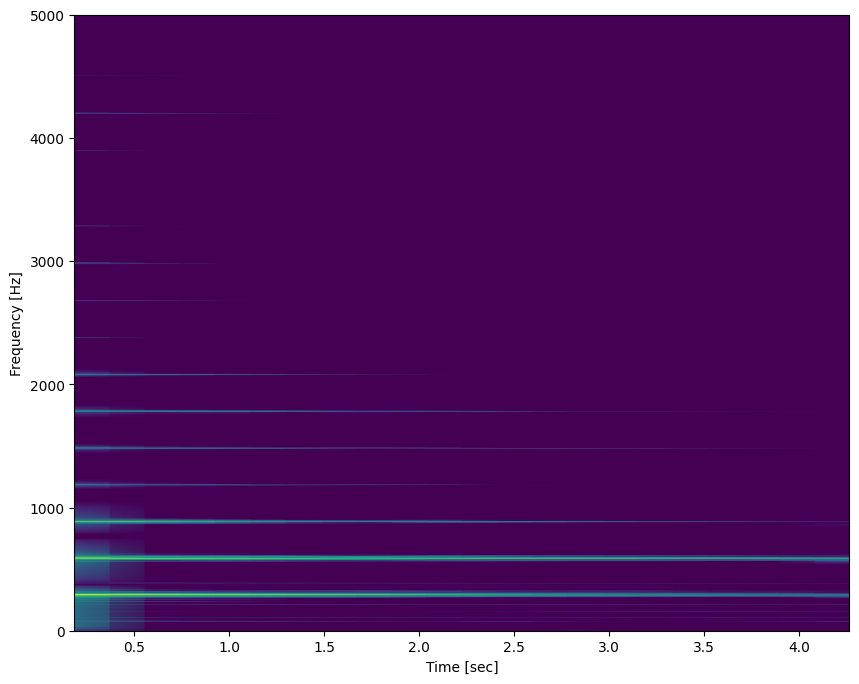

In [9]:
window_length = 8192*2
ff, tt, Sy = signal.spectrogram(x_interf, fs, nperseg=window_length, noverlap=52/2) #Setting to 52 as to follow the input length
ff, tt, S = signal.spectrogram(ref, fs, nperseg=window_length, noverlap=52/2)
plt.figure(figsize=(10,8))
plot_spectrogram(ff, tt, S)
plt.ylim([0, 5000]) #Set vertical range
plt.show()

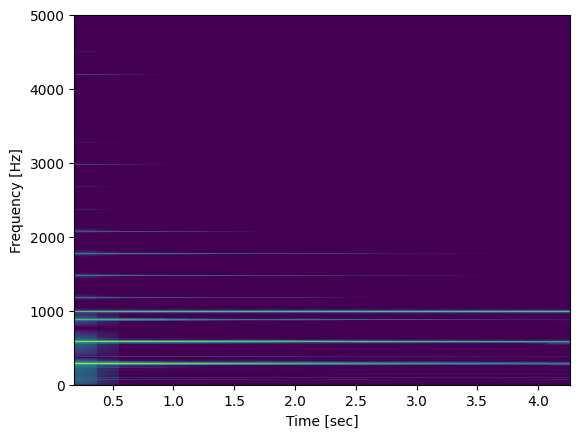

In [10]:
plot_spectrogram(ff, tt, Sy)
plt.ylim([0, 5000]) #Set vertical range
plt.show()

3.4. Create a function `remove_interference(x, fs)` that applies a nulling filter devised to remove the interference at 1000 Hz. 

Note: remember that a frequency can be converted to the normalized radian frequncy by: $\omega_n = 2\pi f_n/f_s$

In [11]:
def remove_interference(x, fs):
    fn = 1000
    wn = 2*np.pi*fn/fs
    return np.convolve(x, [1, -2*np.cos(wn), 1], "same")

3.5 Use the `remove_interference` funcion to clean the corrupted signal,  `x_interf`. Call the output as `x_clean`. Compare the spectrograms of both signals. Explain the result.

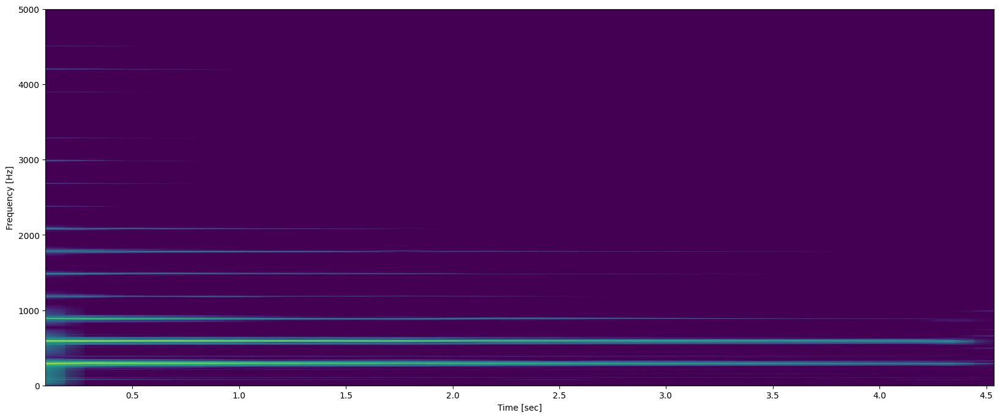

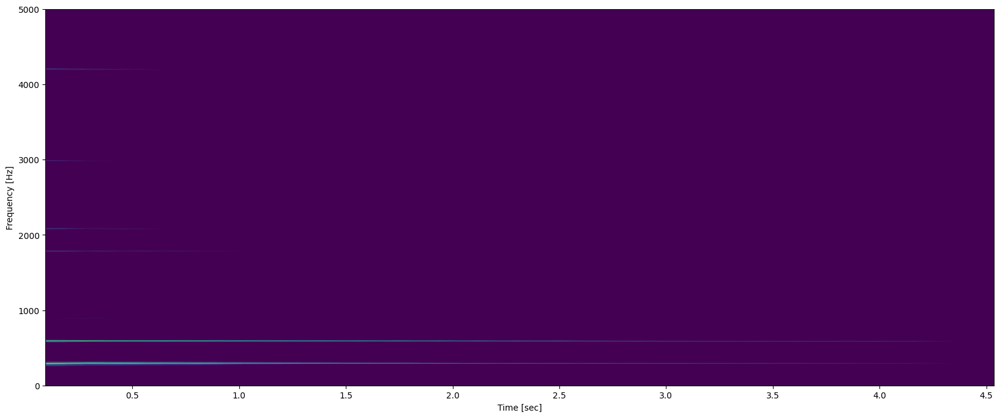

In [12]:
x_clean = remove_interference(x_interf, fs)

window_length = 8192

ff, tt, Sy = signal.spectrogram(x_clean, fs, nperseg=window_length, noverlap=52/2) 
ff, tt, S = signal.spectrogram(ref, fs, nperseg=window_length, noverlap=52/2)

#reference signal
plt.figure(figsize=(20,8))
plot_spectrogram(ff, tt, S)
plt.ylim([0, 5000]) 
plt.show()

#interference signal
plt.figure(figsize=(20,8))
plot_spectrogram(ff, tt, Sy)
plt.ylim([0, 5000])
plt.show()


In [13]:
from IPython.lib.display import Audio
Audio(x_interf, rate=fs)

In [14]:
from IPython.lib.display import Audio
Audio(x_clean, rate=fs)